# Evaluation framework demo

End-to-end demo of the evaluation side of the project:

```
Onion listening events -> sample users + songs -> time-based split -> recommenders (scorers) -> metrics (P/R/NDCG @K) -> ablation table
```

- **Data:** `userid_trackid_timestamp.tsv` (who listened to what, when), `id_musicnn.tsv` (audio embeddings), `id_information.csv` (song/artist names)
- **Time split:** for each user, train on their earlier listens and test on their later ones. A song counts as a hit only if the user listens to it later and hasn't heard it before.
- **Scorers:** every model is a function `history -> one score per song`. The real CF, CNN, LSTM and combined models plug in by exposing the same signature, so `evaluate()` is written once.
- **Stand-ins:** the audio model uses musicnn embeddings (replace with CNN), and the sequence model uses transition counts (replace with LSTM).

NOTE: run `download_music4all_onion.ipynb` first

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Run from the repo root or a subfolder
ROOT = Path.cwd()
if not (ROOT / "datasets").exists() and (ROOT.parent / "datasets").exists():
    ROOT = ROOT.parent
ONION = ROOT / "datasets" / "music4all-onion"
M4A = ROOT / "datasets" / "music4all"
CACHE = ROOT / "datasets" / "cache"
CACHE.mkdir(exist_ok=True)

N_USER_SAMPLE = 4000   # random users to pull from the 119,140 in Onion
N_ITEMS = 3000         # keep the most-listened songs among those users (candidate set)
MIN_UNIQUE = 30        # users need at least this many distinct songs
MAX_UNIQUE = 100       # use each user's most recent N distinct songs
SPLIT = 0.8            # first 80% of a user's songs = history, last 20% = test
K = 10
SEED = 0


1. Load and cache a sample of listening events

In [12]:
cache_file = CACHE / f"listens_seed{SEED}_{N_USER_SAMPLE}.pkl"

if cache_file.exists():
    listens = pd.read_pickle(cache_file)
else:
    wanted = set(np.random.default_rng(SEED).choice(125_000, N_USER_SAMPLE, replace=False))
    parts = []
    for chunk in pd.read_csv(
        ONION / "userid_trackid_timestamp.tsv", sep="\t", chunksize=5_000_000,
        dtype={"user_id": "int32", "track_id": "string"},
    ):
        parts.append(chunk[chunk["user_id"].isin(wanted)])
    listens = pd.concat(parts, ignore_index=True)
    listens["timestamp"] = pd.to_datetime(listens["timestamp"])
    listens.to_pickle(cache_file)

print(f"{len(listens):,} listening events from {listens['user_id'].nunique():,} users")
listens.head()

7,995,427 listening events from 3,801 users


,user_id,track_id,timestamp
0,23761,iD8rTiUcP8HIjfnU,2013-04-08 16:17:10
1,23761,Ydo76vq8wNaO7IaP,2013-03-31 04:18:37
2,23761,30QOYC4uBG4DqoBb,2013-03-31 04:08:56
3,23761,YqIu5MSaS1RNpuMl,2013-03-29 16:56:13
4,23761,kBjlAmjjxLB7Rpsc,2013-03-29 16:49:47


2. Build per-user sequences, keep the `N_ITEMS` most popular songs, and for each user list the distinct songs they listened to in order of first listen. Then split each user's sequence by time.

In [13]:
listens = listens.sort_values(["user_id", "timestamp"])

# Candidate songs: most listeners among the sampled users
first = listens.drop_duplicates(["user_id", "track_id"])
top_items = first["track_id"].value_counts().head(N_ITEMS).index.tolist()
item_index = {t: i for i, t in enumerate(top_items)}

first = first[first["track_id"].isin(item_index)].copy()
first["item"] = first["track_id"].map(item_index).astype(int)

sequences = [
    seq[-MAX_UNIQUE:]
    for seq in first.groupby("user_id")["item"].apply(list)
    if len(seq) >= MIN_UNIQUE
]


def time_split(sequences, frac=SPLIT):
    histories, tests = [], []
    for seq in sequences:
        cut = int(len(seq) * frac)
        histories.append(seq[:cut])
        tests.append(set(seq[cut:]))      # songs are distinct, so none appear in history
    return histories, tests


histories, tests = time_split(sequences)
print(f"{len(sequences):,} users | {N_ITEMS:,} candidate songs")
print(f"avg history length {np.mean([len(h) for h in histories]):.0f}, "
      f"avg test songs per user {np.mean([len(t) for t in tests]):.0f}")

2,512 users | 3,000 candidate songs
avg history length 67, avg test songs per user 17


3. artist/song names, musicnn audio embeddings for the content-based model

In [14]:
musicnn = pd.read_csv(ONION / "id_musicnn.tsv", sep="\t", index_col="id")
item_emb = musicnn.reindex(top_items).to_numpy(dtype=np.float32)
assert not np.isnan(item_emb).any(), "some songs are missing musicnn embeddings"
item_emb = (item_emb - item_emb.mean(axis=0)) / (item_emb.std(axis=0) + 1e-8)   # center for cosine

try:
    info = pd.read_csv(M4A / "id_information.csv", sep="\t", index_col="id").reindex(top_items)
    names = (info["artist"] + " - " + info["song"]).fillna("?").tolist()
except FileNotFoundError:
    names = top_items # No song names available, just use track IDs

print("embedding matrix:", item_emb.shape)
print("example songs:", names[:3])

embedding matrix: (3000, 50)
example songs: ['Nirvana - Come as You Are', 'Foster the People - Pumped Up Kicks', 'Massive Attack - Mezzanine']



4. `scorer(history) -> array with one score per song`. The first four are the individual methods, and the last is the combined model.

In [15]:
def _minmax(x):
    r = x.max() - x.min()
    return (x - x.min()) / r if r > 0 else np.zeros_like(x)


def random_scorer(n_items, seed=SEED):
    rng = np.random.default_rng(seed)
    return lambda history: rng.random(n_items)


def popularity_scorer(train_histories, n_items):
    counts = np.zeros(n_items)
    for h in train_histories:
        counts[h] += 1
    return lambda history: counts


def cf_scorer(train_histories, n_items):
    """Item-item collaborative filtering: songs co-listened by the same users."""
    M = np.zeros((len(train_histories), n_items), dtype=np.float32)
    for u, h in enumerate(train_histories):
        M[u, h] = 1
    norms = np.linalg.norm(M, axis=0) + 1e-9
    sim = (M.T @ M) / np.outer(norms, norms)
    return lambda history: sim[history].sum(axis=0)


def audio_scorer(item_emb):
    """Content-based: similarity to the mean embedding of the user's history."""
    E = item_emb / np.linalg.norm(item_emb, axis=1, keepdims=True)
    def score(history):
        profile = E[history].mean(axis=0)
        return E @ (profile / np.linalg.norm(profile))
    return score


def sequence_scorer(train_histories, n_items, decay=0.5, window=3):
    """Stand-in for the LSTM: next-song transition counts from the last few songs."""
    T = np.zeros((n_items, n_items), dtype=np.float32)
    for h in train_histories:
        for a, b in zip(h, h[1:]):
            T[a, b] += 1
    def score(history):
        out = np.zeros(n_items)
        for lag, item in enumerate(reversed(history[-window:])):
            out += (decay ** lag) * T[item]
        return out
    return score


def hybrid_scorer(parts, weights):
    """Combined model: weighted sum of min-max normalised component scores."""
    def score(history):
        return sum(w * _minmax(s(history)) for s, w in zip(parts, weights))
    return score

5. Metrics and evaluate for every model. Songs a user has already heard are never recommended.

In [16]:
def recommend(scorer, history, k):
    scores = np.asarray(scorer(history), dtype=float).copy()
    scores[history] = -np.inf
    return list(np.argsort(-scores)[:k])


def precision_at_k(recs, relevant):
    return len(set(recs) & relevant) / len(recs)


def recall_at_k(recs, relevant):
    return len(set(recs) & relevant) / len(relevant)


def ndcg_at_k(recs, relevant):
    dcg = sum(1 / np.log2(i + 2) for i, r in enumerate(recs) if r in relevant)
    ideal = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), len(recs))))
    return dcg / ideal


def evaluate(scorer, histories, tests, k=K):
    rows = []
    for hist, rel in zip(histories, tests):
        if not rel:
            continue
        recs = recommend(scorer, hist, k)
        rows.append((precision_at_k(recs, rel), recall_at_k(recs, rel), ndcg_at_k(recs, rel)))
    p, r, n = np.mean(rows, axis=0)
    return {"P@K": p, "R@K": r, "NDCG@K": n}

6. Run the experiment. The ablation rows show the incremental benefit of each added signal. The hybrid weights below are fixed by hand. 

In [17]:
n_items = len(top_items)
pop = popularity_scorer(histories, n_items)
cf = cf_scorer(histories, n_items)
audio = audio_scorer(item_emb)
seq = sequence_scorer(histories, n_items)

models = {
    "Random": random_scorer(n_items),
    "Popularity (baseline)": pop,
    "Collaborative filtering": cf,
    "Audio only (musicnn)": audio,
    "Sequence only": seq,
    "CF + Audio": hybrid_scorer([cf, audio], [0.5, 0.5]),
    "CF + Audio + Sequence": hybrid_scorer([cf, audio, seq], [0.4, 0.3, 0.3]),
}

results = pd.DataFrame({name: evaluate(s, histories, tests) for name, s in models.items()}).T
results.round(4)

,P@K,R@K,NDCG@K
Random,0.0057,0.0035,0.0054
Popularity (baseline),0.0232,0.0144,0.0243
Collaborative filtering,0.0923,0.0646,0.1015
Audio only (musicnn),0.0170,0.0109,0.0176
Sequence only,0.0982,0.0641,0.1330
CF + Audio,0.0761,0.0524,0.0861
CF + Audio + Sequence,0.1042,0.0705,0.1319


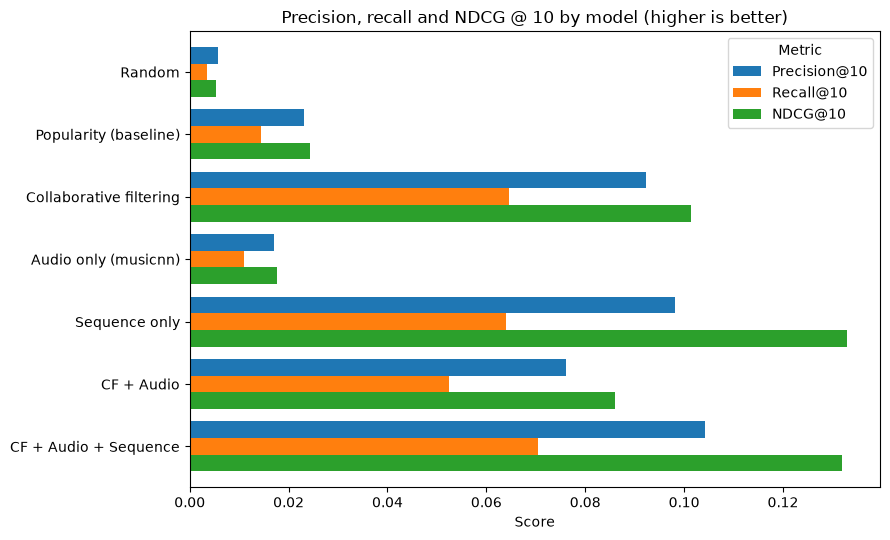

In [18]:
ax = results[["P@K", "R@K", "NDCG@K"]].plot.barh(figsize=(9, 5.5), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Score")
ax.set_title(f"Precision, recall and NDCG @ {K} by model (higher is better)")
ax.legend(title="Metric", labels=[f"Precision@{K}", f"Recall@{K}", f"NDCG@{K}"])
plt.tight_layout()
plt.show()

7. An example of what the combined model recommends for one user, and which of those songs they actually listened to.

In [19]:
user = next(i for i, t in enumerate(tests) if len(t) >= 15)
combined = models["CF + Audio + Sequence"]
recs = recommend(combined, histories[user], K)

print("Recent history:")
for i in histories[user][-5:]:
    print("   ", names[i])
print("\nRecommended (✓ = listened to later):")
for i in recs:
    print("   ", "✓" if i in tests[user] else " ", names[i])

Recent history:
    M83 - Graveyard Girl
    Four Tet - Locked
    Fever Ray - Now's the Only Time I Know
    My Bloody Valentine - Only Shallow
    My Bloody Valentine - Loomer

Recommended (✓ = listened to later):
    ✓ My Bloody Valentine - Touched
      Fever Ray - Keep the Streets Empty for Me
      PJ Harvey - In the Dark Places
      Portishead - Roads
      PJ Harvey - The Glorious Land
      Zero 7 - Destiny
      Fever Ray - Triangle Walks
      Portishead - Glory Box
    ✓ Portishead - Mysterons
      Fever Ray - Seven


## Notes 

- **Sample, not the full dataset:** results come from about 4,000 sampled users and the 3,000 most-listened songs. The same code scales to more, at the cost of the dense item-item matrices. For the full 56k songs, switch to sparse matrices.
- **No validation split yet:** model hyperparameters (hybrid weights, `window`, `decay`) are hand-picked. Add a validation split before tuning.
- **Sequence order:** sequences use each song's *first* listen time, which is a simplification. The real LSTM could use consecutive listens, including repeats.
- **Popularity bias:** restricting to the most-listened songs makes the popularity baseline strong, so report results against it. The sample is also chosen using all users' listens, which slightly favours popular songs.
- **Offline metrics:** a later listen is a weak proxy for "would have liked it". The RL demo uses a simulated user for this reason.